# Tahap 6 — Pemodelan Peramalan (D9)

Notebook ini menerapkan rezim *walk-forward* satu-langkah-ke-depan yang seragam
untuk semua deret gerai×merek. Setiap prediksi D9 hanya menggunakan riwayat
aktual yang tersedia sampai minggu sebelumnya.

In [1]:
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
SEED = int(CFG["seed"])
np.random.seed(SEED)

def rp(*parts: str) -> Path:
    """Resolve a repo-relative path (parts are path fragments under the repo root)."""
    return ROOT.joinpath(*parts)

BRAND_COLORS = {"OPPO": "#0072B2", "Realme": "#D55E00", "Samsung": "#009E73",
                "Vivo": "#CC79A7", "Xiaomi": "#E69F00"}
ALGO_COLORS = {"SARIMAX": "#0072B2", "RF": "#D55E00", "LSTM": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5),
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

Secara default `RETRAIN=False` dan `SAVE_ARTIFACTS=False`: notebook memuat
prediksi D9 yang telah dibundel tanpa melatih ulang atau menimpa artefak mahal.

In [2]:
RETRAIN = False
SAVE_ARTIFACTS = False

## Kontrak data dan utilitas bersama

Seluruh model memakai batas uji D3 yang sama. Fungsi berikut dipindahkan ke
notebook agar jalur pelatihan dapat dipanggil tanpa mengimpor paket proyek.

In [3]:
from abc import ABC, abstractmethod
import logging
import warnings
from pandas.testing import assert_frame_equal

logger = logging.getLogger("notebook.06_modeling")

EXPECTED_PREDICTIONS = (
    "sarimax_baseline", "sarimax_gt", "rf_baseline", "rf_gt",
    "lstm_baseline", "lstm_gt", "naive", "snaive", "croston", "tsb",
    "rf_poisson_baseline", "rf_poisson_gt", "hgb_poisson_baseline",
    "hgb_poisson_gt", "ensemble_mean_baseline", "ensemble_mean_gt",
    "ensemble_invmae_baseline", "ensemble_invmae_gt",
)
PREDICTION_COLUMNS = ["store", "brand", "week_start", "y_true", "y_pred"]
TEST_CALENDAR = pd.date_range("2024-10-21", "2025-06-30", freq="W-MON")


def verify_modeling_outputs(
    retrain: bool,
    save_artifacts: bool,
    modeling_mode: str,
    prediction_catalog: dict[str, pd.DataFrame],
    results_dir: Path,
) -> str:
    """Validate D9 predictions using gates appropriate to the active mode."""
    expected_mode = "retrained" if retrain else "bundled"
    assert modeling_mode == expected_mode, (modeling_mode, expected_mode)
    assert set(prediction_catalog) == set(EXPECTED_PREDICTIONS)
    assert all(isinstance(frame, pd.DataFrame) for frame in prediction_catalog.values())

    for name, frame in prediction_catalog.items():
        assert len(frame) == 740, (name, len(frame))
        assert set(PREDICTION_COLUMNS).issubset(frame.columns), (name, frame.columns.tolist())
        assert not frame[PREDICTION_COLUMNS].isnull().any().any(), name
        assert not frame.duplicated(["store", "brand", "week_start"]).any(), name
        assert np.isfinite(frame[["y_true", "y_pred"]].to_numpy(dtype=float)).all(), name
        assert (frame["y_pred"] >= 0).all(), name
        assert frame.groupby(["store", "brand"]).ngroups == 20, name
        assert frame["week_start"].nunique() == 37, name
        calendar = pd.DatetimeIndex(sorted(pd.to_datetime(frame["week_start"]).unique()))
        assert calendar.equals(TEST_CALENDAR), name
        assert (frame.groupby(["store", "brand"])["week_start"].nunique() == 37).all(), name

    persistence_required = not retrain or save_artifacts
    if persistence_required:
        for name, frame in prediction_catalog.items():
            path = results_dir / f"predictions_{name}.parquet"
            assert path.exists(), path
            persisted = pd.read_parquet(path)
            assert_frame_equal(
                frame.reset_index(drop=True), persisted.reset_index(drop=True),
                check_dtype=True, check_like=False, atol=1e-12, rtol=1e-12,
            )
    if not retrain:
        n_predictions = len(list(results_dir.glob("predictions_*.parquet")))
        assert n_predictions >= len(EXPECTED_PREDICTIONS), n_predictions

    if not retrain:
        return "bundled"
    return "retrained/saved" if save_artifacts else "retrained/no-save"


class Forecaster(ABC):
    @abstractmethod
    def fit(self, y, exog=None) -> "Forecaster":
        """Fit a forecaster on a target and optional exogenous data."""

    @abstractmethod
    def predict(self, horizon: int, exog_future=None) -> np.ndarray:
        """Forecast a horizon or the supplied future design matrix."""

    def name(self) -> str:
        return self.__class__.__name__


def train_cutoff_week(weeks: pd.DatetimeIndex, train_ratio: float = 0.8) -> pd.Timestamp:
    """Return the first test week from the sorted unique full calendar."""
    uniq = pd.DatetimeIndex(sorted(pd.Index(weeks).unique()))
    return uniq[int(np.floor(len(uniq) * train_ratio))]


def temporal_masks(week_series: pd.Series, train_ratio: float = 0.8,
                   cutoff: pd.Timestamp | None = None) -> tuple[pd.Series, pd.Series]:
    """Return chronological train/test masks."""
    if cutoff is None:
        cutoff = train_cutoff_week(pd.DatetimeIndex(week_series), train_ratio)
    is_test = week_series >= cutoff
    return ~is_test, is_test


def resolve_feature_columns(all_cols, cfg, variant: str) -> list[str]:
    """Resolve exact and prefix-wildcard feature specifications in frame order."""
    spec = cfg["feature_variants"][variant]
    resolved = []
    for entry in spec:
        if entry.endswith("*"):
            resolved.extend(c for c in all_cols if c.startswith(entry[:-1]))
        elif entry in all_cols:
            resolved.append(entry)
        else:
            raise KeyError(f"Kolom fitur '{entry}' (varian {variant}) tak ada di features.")
    return list(dict.fromkeys(resolved))


def make_supervised(features_df: pd.DataFrame, cfg, variant: str = "baseline"):
    """Create the past-only supervised matrix used by RF-family models."""
    cols = resolve_feature_columns(features_df.columns, cfg, variant)
    sub = features_df.dropna(subset=cols).reset_index(drop=True)
    return sub[cols].copy(), sub["units"].astype(float).copy(), pd.DatetimeIndex(sub["week_start"])


def _load_series_features(cfg) -> dict[str, pd.DataFrame]:
    """Load the bundled per-series feature tables required by the training path."""
    files = sorted(rp("data", "processed").glob("features_*.parquet"))
    if not files:
        raise FileNotFoundError("Tidak ada data/processed/features_*.parquet")
    out = {}
    for path in files:
        frame = pd.read_parquet(path)
        out[f"{frame['store'].iloc[0]}|{frame['brand'].iloc[0]}"] = frame
    return out


def _load_weekly(cfg) -> pd.DataFrame:
    """Load the authoritative weekly store-brand table without rebuilding upstream data."""
    path = rp("data", "interim", "weekly_store_brand.parquet")
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_parquet(path)


def split_supervised(X, y, index, cutoff):
    """Split a supervised matrix using the common full-calendar cutoff."""
    mask_train, mask_test = temporal_masks(pd.Series(index), cutoff=cutoff)
    return (X.loc[mask_train.values], y.loc[mask_train.values],
            X.loc[mask_test.values], y.loc[mask_test.values],
            pd.DatetimeIndex(index[mask_test.values]))

## SARIMAX — keputusan D6

Kedua varian memakai kalender dan Fourier; hanya varian `gt` menambahkan Google
Trends. Orde musiman tidak dipaksa nonnol. Pada D9, model meramal satu minggu,
lalu state menerima aktual minggu itu melalui `append(refit=False)`.

In [4]:
_LAG_ROLL_PREFIXES = ("lag_", "roll_")


def sarimax_exog_columns(all_cols, cfg, variant: str) -> list[str]:
    cols = resolve_feature_columns(all_cols, cfg, variant)
    return [c for c in cols if not c.startswith(_LAG_ROLL_PREFIXES)]


def split_endog_exog(features_df, cfg, variant, cutoff):
    df = features_df.sort_values("week_start").reset_index(drop=True)
    exog_cols = sarimax_exog_columns(df.columns, cfg, variant)
    mask_train, mask_test = temporal_masks(df["week_start"], cutoff=cutoff)
    y = df["units"].astype(float)
    return (y[mask_train.values].to_numpy(), y[mask_test.values].to_numpy(),
            df.loc[mask_train.values, exog_cols].astype(float),
            df.loc[mask_test.values, exog_cols].astype(float),
            pd.DatetimeIndex(df.loc[mask_test.values, "week_start"]), exog_cols)


class SarimaxForecaster(Forecaster):
    def __init__(self, seasonal=True, m=52, d=None, D=None, max_p=3, max_q=3,
                 max_P=1, max_Q=1, standardize_exog=True):
        self.seasonal, self.m, self.d, self.D = seasonal, m, d, D
        self.max_p, self.max_q, self.max_P, self.max_Q = max_p, max_q, max_P, max_Q
        self.standardize_exog = standardize_exog
        self.model_ = self._res_fixed = self.exog_scaler_ = None
        self.fell_back_, self._order, self._sorder = False, None, None
        self._aic = float("nan")

    def _prep_exog(self, exog, *, fit):
        if exog is None:
            return None
        X = np.asarray(exog, dtype=float)
        if not self.standardize_exog:
            return X
        from sklearn.preprocessing import StandardScaler
        if fit:
            self.exog_scaler_ = StandardScaler().fit(X)
        return self.exog_scaler_.transform(X)

    def fit(self, y, exog=None):
        from pmdarima import auto_arima
        X = self._prep_exog(exog, fit=True)
        common = dict(X=X, d=self.d, max_p=self.max_p, max_q=self.max_q,
                      stepwise=True, error_action="ignore", suppress_warnings=True)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            try:
                self.model_ = auto_arima(y, seasonal=self.seasonal, m=self.m, D=self.D,
                                         max_P=self.max_P, max_Q=self.max_Q, **common)
            except Exception as exc:
                logger.warning("auto_arima seasonal gagal (%s); fallback non-seasonal.", exc)
                self.fell_back_ = True
                self.model_ = auto_arima(y, seasonal=False, **common)
        self._order, self._sorder = tuple(self.model_.order), tuple(self.model_.seasonal_order)
        try:
            self._aic = float(self.model_.aic())
        except Exception:
            self._aic = float("nan")
        return self

    def fit_fixed(self, y, exog, order, seasonal_order, trend=None):
        from statsmodels.tsa.statespace.sarimax import SARIMAX
        X = self._prep_exog(exog, fit=True)
        order, seasonal_order = tuple(map(int, order)), tuple(map(int, seasonal_order))
        trend = trend or ("c" if order[1] == 0 else "n")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            mod = SARIMAX(np.asarray(y, float), exog=X, order=order,
                          seasonal_order=seasonal_order, trend=trend,
                          enforce_stationarity=False, enforce_invertibility=False)
            self._res_fixed = mod.fit(disp=False, maxiter=200)
        self._order, self._sorder, self._aic = order, seasonal_order, float(self._res_fixed.aic)
        return self

    def _statsmodels_result(self):
        return self._res_fixed if self._res_fixed is not None else self.model_.arima_res_

    def walk_forward(self, y_test, exog_test=None):
        cur = self._statsmodels_result()
        Xt = self._prep_exog(exog_test, fit=False) if exog_test is not None else None
        y_test, preds = np.asarray(y_test, float), []
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            for t in range(len(y_test)):
                xf = None if Xt is None else Xt[t:t + 1]
                preds.append(float(np.asarray(cur.forecast(steps=1, exog=xf))[0]))
                cur = cur.append(endog=y_test[t:t + 1], exog=xf, refit=False)
        return np.clip(np.asarray(preds), 0.0, None)

    def predict(self, horizon, exog_future=None):
        X = self._prep_exog(exog_future, fit=False)
        return np.clip(np.asarray(self.model_.predict(n_periods=horizon, X=X), float), 0, None)

    def name(self): return "SARIMAX"
    @property
    def order(self): return self._order
    @property
    def seasonal_order(self): return self._sorder
    @property
    def has_seasonal_terms(self): return bool(sum(self._sorder[:3]) > 0)
    @property
    def aic(self): return self._aic


def _eda_orders(cfg):
    path = rp("reports", "results", "eda_summary.json")
    if not path.exists(): return {}
    adf = json.loads(path.read_text(encoding="utf-8")).get("adf", {})
    return {k: (v.get("recommend_d"), v.get("recommend_D")) for k, v in adf.items()}


def _orders_lookup(orders_df, variant):
    sub = orders_df[orders_df["variant"] == variant]
    return {f"{r.store}|{r.brand}": r for r in sub.itertuples(index=False)}


def fit_one(features_df, cfg, variant, cutoff, d0=None, D0=None, order_row=None, **kwargs):
    y_tr, y_te, X_tr, X_te, idx, cols = split_endog_exog(features_df, cfg, variant, cutoff)
    fc = SarimaxForecaster(m=int(cfg["seasonal_period"]), d=d0, D=D0, **kwargs)
    if order_row is None:
        fc.fit(y_tr, X_tr)
    else:
        fc.fit_fixed(y_tr, X_tr, (order_row.p, order_row.d, order_row.q),
                     (order_row.P, order_row.D, order_row.Q, order_row.m))
    return fc, y_te, fc.walk_forward(y_te, X_te), idx, cols


def train_all_sarimax(cfg, variant, series=None, save=True, orders_df=None, **kwargs):
    feats = _load_series_features(cfg)
    if series is not None: feats = {k: v for k, v in feats.items() if k in series}
    grid = pd.DatetimeIndex(sorted(next(iter(feats.values()))["week_start"].unique()))
    cutoff, eda = train_cutoff_week(grid, float(cfg["train_ratio"])), _eda_orders(cfg)
    lookup = _orders_lookup(orders_df, variant) if orders_df is not None else {}
    pred_rows, order_rows = [], []
    for key, df in feats.items():
        store, brand = key.split("|"); d0, D0 = eda.get(key, (None, None))
        fc, yt, yp, idx, _ = fit_one(df, cfg, variant, cutoff, d0, D0, lookup.get(key), **kwargs)
        pred_rows.append(pd.DataFrame({"store": store, "brand": brand, "week_start": idx,
                                       "y_true": yt, "y_pred": yp}))
        p, d, q = fc.order; P, D, Q, m = fc.seasonal_order
        order_rows.append({"store": store, "brand": brand, "variant": variant,
                           "p": p, "d": d, "q": q, "P": P, "D": D, "Q": Q, "m": m,
                           "has_seasonal_terms": fc.has_seasonal_terms,
                           "fell_back": fc.fell_back_, "aic": round(fc.aic, 2)})
    predictions, orders = pd.concat(pred_rows, ignore_index=True), pd.DataFrame(order_rows)
    if save:
        predictions.to_parquet(rp("reports", "results", f"predictions_sarimax_{variant}.parquet"), index=False)
    return predictions, orders

## Random Forest — keputusan D4

GridSearchCV memakai `TimeSeriesSplit` hanya pada data latih. Fitur lag dan
rolling pada setiap minggu uji berasal dari aktual sampai t−1, sehingga seluruh
37 keluaran tetap ramalan satu-langkah-ke-depan.

In [5]:
def _param_grid(cfg):
    rf = cfg["random_forest"]
    return {k: rf[k] for k in ("n_estimators", "max_depth", "max_features", "min_samples_leaf")}


class RandomForestForecaster(Forecaster):
    def __init__(self, param_grid, cv_splits=5, random_state=42,
                 scoring="neg_mean_absolute_error", n_jobs=-1):
        self.param_grid, self.cv_splits, self.random_state = param_grid, cv_splits, random_state
        self.scoring, self.n_jobs = scoring, n_jobs
        self.model_ = self.best_params_ = self.feature_names_ = None

    def fit(self, X, y=None):
        from sklearn.ensemble import RandomForestRegressor
        from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
        self.feature_names_ = list(X.columns)
        gs = GridSearchCV(RandomForestRegressor(random_state=self.random_state, n_jobs=self.n_jobs),
                          self.param_grid, cv=TimeSeriesSplit(self.cv_splits),
                          scoring=self.scoring, n_jobs=self.n_jobs).fit(X, y)
        self.model_, self.best_params_ = gs.best_estimator_, gs.best_params_
        return self

    def predict(self, X, exog_future=None): return np.clip(self.model_.predict(X), 0, None)
    @property
    def feature_importances_(self): return self.model_.feature_importances_
    def name(self): return "RandomForest"


def _plot_importance(fc, key, variant, out_path):
    imp = pd.Series(fc.feature_importances_, index=fc.feature_names_).sort_values()
    fig, ax = plt.subplots(figsize=(8, max(4, .28 * len(imp))))
    ax.barh(imp.index, imp.values, color=["#C44E52" if n == "gt_index" else "#4C72B0" for n in imp.index])
    ax.set(title=f"Kepentingan fitur RF — {key} [{variant}]", xlabel="kepentingan")
    fig.tight_layout(); fig.savefig(out_path, dpi=110); plt.close(fig)


def train_all_rf(cfg, variant, series=None, save=True, param_grid=None, **kwargs):
    feats = _load_series_features(cfg)
    if series is not None: feats = {k: v for k, v in feats.items() if k in series}
    grid = pd.DatetimeIndex(sorted(next(iter(feats.values()))["week_start"].unique()))
    cutoff = train_cutoff_week(grid, float(cfg["train_ratio"]))
    pred_rows, param_rows = [], []
    for key, df in feats.items():
        store, brand = key.split("|"); X, y, idx = make_supervised(df, cfg, variant)
        Xtr, ytr, Xte, yte, tidx = split_supervised(X, y, idx, cutoff)
        fc = RandomForestForecaster(param_grid or _param_grid(cfg), random_state=int(cfg["seed"]), **kwargs).fit(Xtr, ytr)
        yp = fc.predict(Xte)
        pred_rows.append(pd.DataFrame({"store": store, "brand": brand, "week_start": tidx,
                                       "y_true": yte.to_numpy(), "y_pred": yp}))
        param_rows.append({"store": store, "brand": brand, "variant": variant, **fc.best_params_})
        if save:
            import joblib
            mdir = rp("models", "random_forest", variant); mdir.mkdir(parents=True, exist_ok=True)
            joblib.dump(fc.model_, mdir / f"{store}_{brand}.pkl")
            fdir = rp("reports", "figures"); fdir.mkdir(parents=True, exist_ok=True)
            _plot_importance(fc, key, variant, fdir / f"rf_importance_{store}_{brand}_{variant}.png")
    predictions, params = pd.concat(pred_rows, ignore_index=True), pd.DataFrame(param_rows)
    if save: predictions.to_parquet(rp("reports", "results", f"predictions_rf_{variant}.parquet"), index=False)
    return predictions, params

## LSTM

Jendela LSTM berakhir di t−1 dan berisi aktual, kalender, Fourier, tren, serta
`gt_index` hanya untuk varian GT. TensorFlow/Keras baru diimpor ketika pelatihan
benar-benar dipanggil.

In [6]:
def lstm_channels(all_cols, cfg, variant): return ["units"] + sarimax_exog_columns(all_cols, cfg, variant)


def make_sequences(channels_scaled, y_scaled, week_start, L):
    X, y, idx = [], [], []
    for t in range(L, len(y_scaled)):
        X.append(channels_scaled[t-L:t]); y.append(y_scaled[t]); idx.append(week_start[t])
    return np.asarray(X, dtype="float32"), np.asarray(y, dtype="float32"), pd.DatetimeIndex(idx)


def build_series_sequences(features_df, cfg, variant, cutoff):
    from sklearn.preprocessing import MinMaxScaler
    df = features_df.sort_values("week_start").reset_index(drop=True)
    channels, weeks = lstm_channels(df.columns, cfg, variant), pd.DatetimeIndex(df["week_start"])
    mat, L = df[channels].astype(float).to_numpy(), int(cfg["lags"])
    scaler = MinMaxScaler().fit(mat[weeks < cutoff]); mat_s = scaler.transform(mat)
    umin, umax = scaler.data_min_[0], scaler.data_max_[0]; urange = (umax - umin) or 1.0
    X, y, idx = make_sequences(mat_s, (mat[:, 0] - umin) / urange, weeks, L)
    tr, te = (m.values for m in temporal_masks(pd.Series(idx), cutoff=cutoff))
    y_true = df.loc[df["week_start"].isin(idx[te]), "units"].astype(float).to_numpy()
    return X[tr], y[tr], X[te], idx[te], y_true, float(umin), float(urange)


class LSTMForecaster(Forecaster):
    def __init__(self, units=64, dropout=.2, epochs=200, batch_size=16,
                 patience=10, val_frac=.2, seed=42):
        self.units, self.dropout, self.epochs, self.batch_size = units, dropout, epochs, batch_size
        self.patience, self.val_frac, self.seed, self.model_ = patience, val_frac, seed, None

    def _build(self, n_steps, n_channels):
        import keras
        from keras import layers
        keras.utils.set_random_seed(self.seed)
        model = keras.Sequential([keras.Input((n_steps, n_channels)), layers.LSTM(self.units),
                                  layers.Dropout(self.dropout), layers.Dense(1)])
        model.compile(loss="mse", optimizer="adam"); return model

    def fit(self, X, y=None):
        import keras
        self.model_ = self._build(X.shape[1], X.shape[2])
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience,
                                           restore_best_weights=True)
        self.model_.fit(X, y, epochs=self.epochs, batch_size=self.batch_size,
                        validation_split=self.val_frac, shuffle=False, callbacks=[es], verbose=0)
        return self

    def predict(self, X, exog_future=None): return self.model_.predict(X, verbose=0).ravel()
    def name(self): return "LSTM"


def train_all_lstm(cfg, variant, series=None, save=True, **kwargs):
    feats = _load_series_features(cfg)
    if series is not None: feats = {k: v for k, v in feats.items() if k in series}
    grid = pd.DatetimeIndex(sorted(next(iter(feats.values()))["week_start"].unique()))
    cutoff = train_cutoff_week(grid, float(cfg["train_ratio"]))
    params = {"units": cfg.get("lstm", {}).get("units", 64), "dropout": cfg.get("lstm", {}).get("dropout", .2),
              "epochs": cfg.get("lstm", {}).get("epochs", 200), "batch_size": cfg.get("lstm", {}).get("batch_size", 16),
              "patience": cfg.get("lstm", {}).get("patience", 10)}; params.update(kwargs)
    rows = []
    for key, df in feats.items():
        store, brand = key.split("|")
        Xtr, ytr, Xte, idx, yt, umin, urange = build_series_sequences(df, cfg, variant, cutoff)
        fc = LSTMForecaster(seed=int(cfg["seed"]), **params).fit(Xtr, ytr)
        yp = np.clip(fc.predict(Xte) * urange + umin, 0, None)
        rows.append(pd.DataFrame({"store": store, "brand": brand, "week_start": idx,
                                  "y_true": yt, "y_pred": yp}))
        if save:
            import joblib
            mdir = rp("models", "lstm", variant); mdir.mkdir(parents=True, exist_ok=True)
            fc.model_.save(mdir / f"{store}_{brand}.keras")
            joblib.dump({"units_min": umin, "units_range": urange},
                        mdir / f"scaler_{store}_{brand}.pkl")
    predictions = pd.concat(rows, ignore_index=True)
    if save: predictions.to_parquet(rp("reports", "results", f"predictions_lstm_{variant}.parquet"), index=False)
    return predictions

## Baseline naif — keputusan D10

Naif lag-1 dan seasonal-naive lag-52 tidak mengikuti ranking algoritma utama;
keduanya menjadi pembanding serta denominator MASE pada origin D9 yang sama.

In [7]:
NAIVE_METHODS = ("naive", "snaive")


def one_step_naive(units, seasonal, m=52):
    u = np.asarray(units, float); fc = np.full(len(u), np.nan)
    for t in range(len(u)):
        if seasonal and t-m >= 0: fc[t] = u[t-m]
        elif t-1 >= 0: fc[t] = u[t-1]
    return np.clip(fc, 0, None)


def build_naive_predictions(cfg, method):
    if method not in NAIVE_METHODS: raise ValueError(f"metode naif tak dikenal: {method}")
    weekly = _load_weekly(cfg); grid = pd.DatetimeIndex(sorted(weekly["week_start"].unique()))
    cutoff, rows = train_cutoff_week(grid, float(cfg["train_ratio"])), []
    for (store, brand), sub in weekly.groupby(["store", "brand"]):
        sub = sub.sort_values("week_start").reset_index(drop=True); test = sub["week_start"] >= cutoff
        fc = one_step_naive(sub["units"], method == "snaive", int(cfg["seasonal_period"]))
        rows.append(pd.DataFrame({"store": store, "brand": brand,
                                  "week_start": sub.loc[test, "week_start"].to_numpy(),
                                  "y_true": sub.loc[test, "units"].astype(float).to_numpy(),
                                  "y_pred": fc[test.to_numpy()]}))
    return pd.concat(rows, ignore_index=True)


def train_all_naive(cfg, save=True):
    out = {method: build_naive_predictions(cfg, method) for method in NAIVE_METHODS}
    if save:
        for method, df in out.items(): df.to_parquet(rp("reports", "results", f"predictions_{method}.parquet"), index=False)
    return out

## Kandidat D11

Croston/TSB menangani permintaan intermittent; RF/HGB Poisson menyelaraskan loss
dengan data hitungan; ensemble menggabungkan RF dan LSTM tanpa fitting model baru.

In [8]:
METHODS = ("croston", "tsb")
ALPHA_GRID = (.05, .1, .15, .2, .3, .4, .5)


def croston_forecast(y, alpha):
    y = np.asarray(y, float); fc = np.zeros(len(y)); z = p = None; q = 0
    for t in range(len(y)):
        fc[t] = z/p if z is not None and p and p > 0 else 0.; q += 1
        if y[t] > 0:
            if z is None: z, p = y[t], float(q)
            else: z, p = alpha*y[t] + (1-alpha)*z, alpha*q + (1-alpha)*p
            q = 0
    return np.clip(fc, 0, None)


def tsb_forecast(y, alpha, beta=None):
    y = np.asarray(y, float); beta = alpha if beta is None else beta
    fc = np.zeros(len(y)); z, prob = None, 0.
    for t in range(len(y)):
        fc[t] = prob*z if z is not None else 0.
        if y[t] > 0: z = y[t] if z is None else alpha*y[t] + (1-alpha)*z; prob = beta + (1-beta)*prob
        else: prob = (1-beta)*prob
    return np.clip(fc, 0, None)


_FORECASTERS = {"croston": croston_forecast, "tsb": tsb_forecast}


def tune_alpha(y_full, n_train, method):
    best_alpha, best_mae = ALPHA_GRID[0], np.inf
    for alpha in ALPHA_GRID:
        fc = _FORECASTERS[method](y_full, alpha)
        mae = float(np.mean(np.abs(np.asarray(y_full, float)[1:n_train] - fc[1:n_train])))
        if mae < best_mae: best_alpha, best_mae = alpha, mae
    return best_alpha


def train_all_croston(cfg, method, save=True):
    if method not in METHODS: raise ValueError(f"metode tak dikenal: {method}")
    weekly = _load_weekly(cfg); grid = pd.DatetimeIndex(sorted(weekly["week_start"].unique()))
    cutoff = train_cutoff_week(grid, float(cfg["train_ratio"])); n_train = int((grid < cutoff).sum())
    rows, params = [], []
    for (store, brand), sub in weekly.groupby(["store", "brand"]):
        sub = sub.sort_values("week_start").reset_index(drop=True); y = sub["units"].to_numpy(float)
        alpha = tune_alpha(y, n_train, method); fc = _FORECASTERS[method](y, alpha)
        test = (sub["week_start"] >= cutoff).to_numpy()
        rows.append(pd.DataFrame({"store": store, "brand": brand,
                                  "week_start": sub.loc[test, "week_start"].to_numpy(),
                                  "y_true": y[test], "y_pred": fc[test]}))
        params.append({"method": method, "store": store, "brand": brand, "alpha": alpha})
    predictions, params = pd.concat(rows, ignore_index=True), pd.DataFrame(params)
    if save: predictions.to_parquet(rp("reports", "results", f"predictions_{method}.parquet"), index=False)
    return predictions, params


KINDS = ("rf_poisson", "hgb_poisson")


def _estimator_and_grid(kind, cfg, seed):
    if kind == "rf_poisson":
        from sklearn.ensemble import RandomForestRegressor
        rf = cfg["random_forest"]
        return RandomForestRegressor(criterion="poisson", random_state=seed, n_jobs=-1), _param_grid(cfg)
    if kind == "hgb_poisson":
        from sklearn.ensemble import HistGradientBoostingRegressor
        return HistGradientBoostingRegressor(loss="poisson", random_state=seed, early_stopping=False, max_iter=400), {
            "learning_rate": [.05, .1], "max_leaf_nodes": [8, 15], "min_samples_leaf": [10, 20]}
    raise ValueError(f"kind tak dikenal: {kind}")


def _fit_predict(kind, Xtr, ytr, Xte, cfg, seed):
    from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
    est, grid = _estimator_and_grid(kind, cfg, seed)
    gs = GridSearchCV(est, grid, cv=TimeSeriesSplit(5), scoring="neg_mean_absolute_error", n_jobs=-1).fit(Xtr, ytr)
    return np.clip(gs.best_estimator_.predict(Xte), 0, None), gs.best_params_


def train_all_poisson(cfg, kind, variant, series=None, save=True):
    feats = _load_series_features(cfg)
    if series is not None: feats = {k: v for k, v in feats.items() if k in series}
    grid = pd.DatetimeIndex(sorted(next(iter(feats.values()))["week_start"].unique()))
    cutoff, rows, params = train_cutoff_week(grid, float(cfg["train_ratio"])), [], []
    for key, df in feats.items():
        store, brand = key.split("|"); X, y, idx = make_supervised(df, cfg, variant)
        Xtr, ytr, Xte, yte, tidx = split_supervised(X, y, idx, cutoff)
        yp, best = _fit_predict(kind, Xtr, ytr, Xte, cfg, int(cfg["seed"]))
        rows.append(pd.DataFrame({"store": store, "brand": brand, "week_start": tidx,
                                  "y_true": yte.to_numpy(), "y_pred": yp}))
        params.append({"kind": kind, "store": store, "brand": brand, "variant": variant, **best})
    predictions, params = pd.concat(rows, ignore_index=True), pd.DataFrame(params)
    if save: predictions.to_parquet(rp("reports", "results", f"predictions_{kind}_{variant}.parquet"), index=False)
    return predictions, params


VARIANTS, _KEYS, _EPS = ("baseline", "gt"), ["store", "brand", "week_start"], 1e-6


def _load_pair(results_dir, variant):
    return (pd.read_parquet(results_dir / f"predictions_rf_{variant}.parquet"),
            pd.read_parquet(results_dir / f"predictions_lstm_{variant}.parquet"))


def _merge_pair(rf, lstm):
    m = rf[_KEYS + ["y_true", "y_pred"]].merge(lstm[_KEYS + ["y_true", "y_pred"]],
                                                 on=_KEYS, suffixes=("_rf", "_lstm"))
    if len(m) != len(rf) or len(m) != len(lstm): raise ValueError("Origin RF & LSTM tak sepadan (D9).")
    if not np.allclose(m["y_true_rf"], m["y_true_lstm"]): raise ValueError("y_true RF & LSTM berbeda (D9).")
    return m


def ensemble_mean(m): return np.clip(.5*m["y_pred_rf"].to_numpy() + .5*m["y_pred_lstm"].to_numpy(), 0, None)


def ensemble_invmae_series(y_true, p_rf, p_lstm):
    y_true, p_rf, p_lstm = map(lambda a: np.asarray(a, float), (y_true, p_rf, p_lstm)); out = np.zeros(len(y_true))
    for i in range(len(y_true)):
        if i == 0: wr = wl = .5
        else:
            ir = 1/(np.mean(np.abs(y_true[:i]-p_rf[:i]))+_EPS); il = 1/(np.mean(np.abs(y_true[:i]-p_lstm[:i]))+_EPS)
            wr, wl = ir/(ir+il), il/(ir+il)
        out[i] = wr*p_rf[i] + wl*p_lstm[i]
    return np.clip(out, 0, None)


def build_variant(results_dir, variant):
    rf, lstm = _load_pair(results_dir, variant); out = {"mean": [], "invmae": []}
    for (store, brand), g in _merge_pair(rf, lstm).groupby(["store", "brand"]):
        g = g.sort_values("week_start"); base = {"store": store, "brand": brand,
            "week_start": g["week_start"].to_numpy(), "y_true": g["y_true_rf"].to_numpy()}
        out["mean"].append(pd.DataFrame({**base, "y_pred": ensemble_mean(g)}))
        out["invmae"].append(pd.DataFrame({**base, "y_pred": ensemble_invmae_series(g["y_true_rf"], g["y_pred_rf"], g["y_pred_lstm"])}))
    return {k: pd.concat(v, ignore_index=True) for k, v in out.items()}


def train_all_ensemble(cfg, save=True):
    out = {}
    for variant in VARIANTS:
        for scheme, df in build_variant(rp("reports", "results"), variant).items():
            name = f"ensemble_{scheme}_{variant}"; out[name] = df
            if save: df.to_parquet(rp("reports", "results", f"predictions_{name}.parquet"), index=False)
    return out

## Jalur eksekusi

Pada eksekusi dokumentasi ini, prediksi yang dibundel dimuat apa adanya. Pelatihan
ulang bersifat manual dan mahal; artefak hanya ditulis bila kedua sakelar diaktifkan.

In [9]:
if RETRAIN:
    modeling_mode = "retrained"
    prediction_catalog, fitted_orders = {}, []
    for variant in VARIANTS:
        prediction_catalog[f"sarimax_{variant}"], orders = train_all_sarimax(
            CFG, variant, save=SAVE_ARTIFACTS)
        fitted_orders.append(orders)
        prediction_catalog[f"rf_{variant}"], _ = train_all_rf(CFG, variant, save=SAVE_ARTIFACTS)
        prediction_catalog[f"lstm_{variant}"] = train_all_lstm(CFG, variant, save=SAVE_ARTIFACTS)
    prediction_catalog.update(train_all_naive(CFG, save=SAVE_ARTIFACTS))
    for method in METHODS:
        prediction_catalog[method], _ = train_all_croston(CFG, method, save=SAVE_ARTIFACTS)
    for kind in KINDS:
        for variant in VARIANTS:
            prediction_catalog[f"{kind}_{variant}"], _ = train_all_poisson(
                CFG, kind, variant, save=SAVE_ARTIFACTS)
    for variant in VARIANTS:
        rf, lstm = prediction_catalog[f"rf_{variant}"], prediction_catalog[f"lstm_{variant}"]
        merged = _merge_pair(rf, lstm)
        for scheme in ("mean", "invmae"):
            pieces = []
            for (store, brand), g in merged.groupby(["store", "brand"]):
                g = g.sort_values("week_start")
                yp = ensemble_mean(g) if scheme == "mean" else ensemble_invmae_series(
                    g["y_true_rf"], g["y_pred_rf"], g["y_pred_lstm"])
                pieces.append(pd.DataFrame({"store": store, "brand": brand,
                    "week_start": g["week_start"].to_numpy(), "y_true": g["y_true_rf"].to_numpy(), "y_pred": yp}))
            name = f"ensemble_{scheme}_{variant}"; prediction_catalog[name] = pd.concat(pieces, ignore_index=True)
            if SAVE_ARTIFACTS: prediction_catalog[name].to_parquet(rp("reports", "results", f"predictions_{name}.parquet"), index=False)
    fitted_orders = pd.concat(fitted_orders, ignore_index=True)
    print("Jumlah fit SARIMAX dengan orde musiman nonnol:", int(fitted_orders["has_seasonal_terms"].sum()))
else:
    modeling_mode = "bundled"
    prediction_catalog = {
        name: pd.read_parquet(rp("reports", "results", f"predictions_{name}.parquet"))
        for name in EXPECTED_PREDICTIONS
    }
    print("Mode bundel aktif: tidak ada model yang dilatih dan tidak ada artefak yang ditimpa.")
    print("Catatan Bab IV: 12 dari 40 fit SARIMAX dilaporkan memiliki orde musiman nonnol; angka ini bukan hasil hitung ulang notebook.")

Mode bundel aktif: tidak ada model yang dilatih dan tidak ada artefak yang ditimpa.
Catatan Bab IV: 12 dari 40 fit SARIMAX dilaporkan memiliki orde musiman nonnol; angka ini bukan hasil hitung ulang notebook.


## Contoh perbandingan aktual dan prediksi

Overlay berikut memakai satu deret gerai–merek nyata agar pola mingguan tetap
terbaca, dengan tiga algoritma utama pada varian baseline.

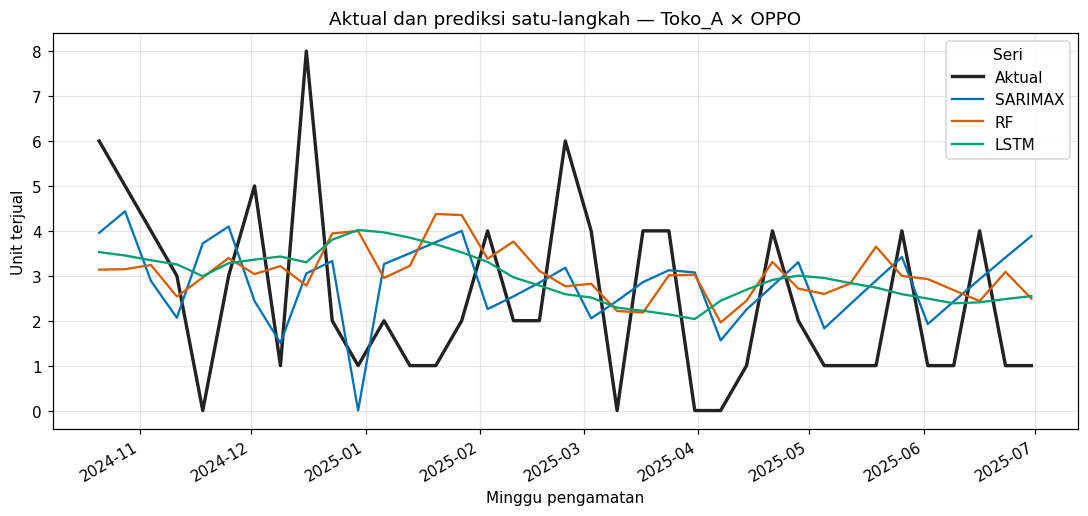

In [10]:
representative = prediction_catalog["sarimax_baseline"][["store", "brand"]].iloc[0]
sel_store, sel_brand = representative["store"], representative["brand"]
fig_actual_pred, ax_actual_pred = plt.subplots(figsize=(10, 4.8))
base = prediction_catalog["sarimax_baseline"].query("store == @sel_store and brand == @sel_brand").sort_values("week_start")
ax_actual_pred.plot(base["week_start"], base["y_true"], color="#222222", lw=2.2, label="Aktual")
for algo, key in (("SARIMAX", "sarimax_baseline"), ("RF", "rf_baseline"), ("LSTM", "lstm_baseline")):
    part = prediction_catalog[key].query("store == @sel_store and brand == @sel_brand").sort_values("week_start")
    ax_actual_pred.plot(part["week_start"], part["y_pred"], color=ALGO_COLORS[algo], lw=1.5, label=algo)
ax_actual_pred.set_title(f"Aktual dan prediksi satu-langkah — {sel_store} × {sel_brand}")
ax_actual_pred.set_xlabel("Minggu pengamatan")
ax_actual_pred.set_ylabel("Unit terjual")
ax_actual_pred.legend(title="Seri")
fig_actual_pred.autofmt_xdate(); fig_actual_pred.tight_layout()
plt.show()

In [11]:
verified_modeling_mode = verify_modeling_outputs(
    RETRAIN,
    SAVE_ARTIFACTS,
    modeling_mode,
    prediction_catalog,
    rp("reports", "results"),
)

assert fig_actual_pred.axes and ax_actual_pred in fig_actual_pred.axes
assert len(ax_actual_pred.lines) >= 2 and all(len(line.get_xdata()) > 0 for line in ax_actual_pred.lines)
assert ax_actual_pred.get_title() and ax_actual_pred.get_xlabel() and ax_actual_pred.get_ylabel()
assert ax_actual_pred.get_legend() is not None and ax_actual_pred.get_legend().get_visible()
print(f"✅ Tahap 6 [{verified_modeling_mode}]: prediksi one-step D9 lengkap "
      "(6 utama×740, naif, ≥10 kandidat D11)")

✅ Tahap 6 [bundled]: prediksi one-step D9 lengkap (6 utama×740, naif, ≥10 kandidat D11)
